# Notebook 04 — Calibrate the keywords with `gtab` (one country at a time)

**Project:** Searching for Work in Germany: Google Trends Signals of Labour Migration Interest and Policy Effects (focus: migrant care workers)
**Author:** Tayaphon Rodsai

---

### What this notebook does

For **one country** it:
1. builds the `gtab` **anchor bank** (or loads it if it already exists),
2. **calibrates** the country's final keywords (from Notebook 02), and
3. calibrates two **reference searches** (the topics *Germany* and *YouTube*), which we may use later to compare countries (RQ1).

Every result is saved, so nothing is downloaded twice.

### How to use it

1. Change `COUNTRY` in the next cell (e.g. `"PH"`).
2. **Restart** the kernel, then **Run All**.
3. Building a new anchor bank sends several hundred Google requests (about 15–25 minutes). Run **one country per day**. If Google blocks (`429` or `google.com/sorry`), stop and run again later — finished steps are saved.

**Software note:** `gtab` 0.8 needed 7 small fixes to run with Python 3.14 and pandas 3. They are documented in `patches/gtab_0.8_core.patch`.

*Reference: West, R. (2020). Calibration of Google Trends Time Series. CIKM 2020.*

## 1. Settings

In [1]:
COUNTRY = "VN"          # change this: VN, PH, IN, TR, ID, MA, TN, BA, CM

TIMEFRAME = "2015-01-01 2026-10-31"

# Smaller anchor bank than gtab's default (550 anchors) -> about half the Google requests.
# Viet Nam was built with the default settings before this notebook existed.
GTAB_CONFIG = {"num_anchor_candidates": 1600, "num_anchors": 250}

# Reference searches calibrated in every country (Google "topics", the same in all languages)
REFERENCES = {"ref_topic_germany": "/m/0345h", "ref_topic_youtube": "/m/09jcvs"}

## 2. Load the fixed `gtab` and the keywords

In [2]:
import importlib, inspect
from pathlib import Path

import numpy as np
import pandas as pd
import gtab, gtab.core

importlib.reload(gtab.core)          # make sure the fixed version is used
importlib.reload(gtab)
print("Fixed gtab loaded:", "PATCH" in inspect.getsource(gtab.core))

PROCESSED = Path("../data/processed")
OUT = PROCESSED / "gtab"
OUT.mkdir(parents=True, exist_ok=True)

final = pd.read_csv(PROCESSED / "keywords_final.csv")
keywords = final[final["code"] == COUNTRY][["country", "theme", "keyword", "status"]]
keywords

Fixed gtab loaded: True


,country,theme,keyword,status
17,Viet Nam,care,điều dưỡng đức,strong
18,Viet Nam,training,du học nghề đức,strong
19,Viet Nam,work,xuất khẩu lao động đức,usable


## 3. Anchor bank

If the bank for this country already exists, `gtab` only prints *"GTAB with such parameters already exists"* — that is fine.

In [3]:
t = gtab.GTAB(dir_path="../data/gtab_workspace")
t.set_options(pytrends_config={"geo": COUNTRY, "timeframe": TIMEFRAME},
              gtab_config=None if COUNTRY == "VN" else GTAB_CONFIG)
t.create_anchorbank()

BANK = f"google_anchorbank_geo={COUNTRY}_timeframe={TIMEFRAME}.tsv"
t.set_active_gtab(BANK)

Directory already exists, loading data from it.
Using directory '../data/gtab_workspace'
Active anchorbank changed to: google_anchorbank_geo=_timeframe=2019-01-01 2020-08-01.tsv

Start AnchorBank init for region VN in timeframe 2015-01-01 2026-10-31...
GTAB with such parameters already exists! Load it with 'set_active_gtab(filename)' or rename/delete it to create another one with this name.
Active anchorbank changed to: google_anchorbank_geo=VN_timeframe=2015-01-01 2026-10-31.tsv



## 4. Calibrate the keywords and the reference searches

Each query needs only a few Google requests. Results are saved as `data/processed/gtab/{COUNTRY}_{name}.csv`; queries that are already saved are skipped.

In [4]:
queries = {row["theme"]: row["keyword"] for _, row in keywords.iterrows()}
queries.update(REFERENCES)

for name, query in queries.items():
    path = OUT / f"{COUNTRY}_{name}.csv"
    if path.exists():
        print(f"already saved: {path.name}")
        continue
    result = t.new_query(query)
    if result is None or len(result) == 0:
        print(f"could not calibrate: {name} ({query})")
        continue
    result.insert(0, "query", query)
    result.to_csv(path)
    print(f"saved: {path.name}")

Using ../data/gtab_workspace\output\google_anchorbanks\google_anchorbank_geo=VN_timeframe=2015-01-01 2026-10-31.tsv
New query 'điều dưỡng đức'
New query calibrated!
saved: VN_care.csv
Using ../data/gtab_workspace\output\google_anchorbanks\google_anchorbank_geo=VN_timeframe=2015-01-01 2026-10-31.tsv
New query 'du học nghề đức'
New query calibrated!
saved: VN_training.csv
Using ../data/gtab_workspace\output\google_anchorbanks\google_anchorbank_geo=VN_timeframe=2015-01-01 2026-10-31.tsv
New query 'xuất khẩu lao động đức'
New query calibrated!
saved: VN_work.csv
Using ../data/gtab_workspace\output\google_anchorbanks\google_anchorbank_geo=VN_timeframe=2015-01-01 2026-10-31.tsv
New query '/m/0345h'
New query calibrated!
saved: VN_ref_topic_germany.csv
Using ../data/gtab_workspace\output\google_anchorbanks\google_anchorbank_geo=VN_timeframe=2015-01-01 2026-10-31.tsv
New query '/m/09jcvs'
New query calibrated!
saved: VN_ref_topic_youtube.csv


## 5. Quick look

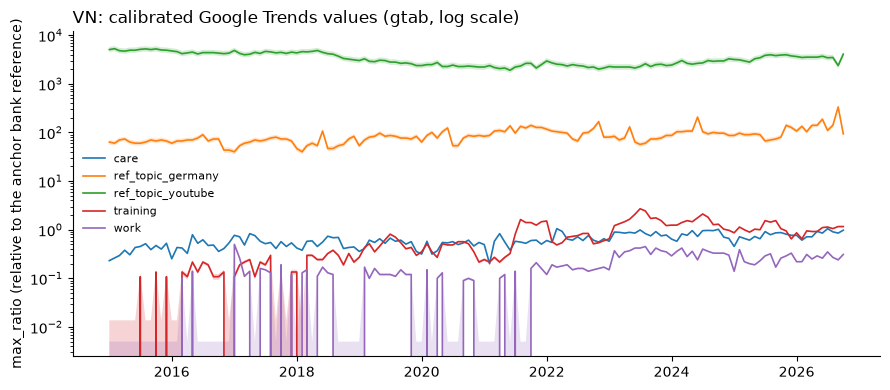

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
for path in sorted(OUT.glob(f"{COUNTRY}_*.csv")):
    r = pd.read_csv(path, index_col=0, parse_dates=True)
    name = path.stem.replace(f"{COUNTRY}_", "")
    ax.plot(r.index, r["max_ratio"], label=name, linewidth=1.2)
    ax.fill_between(r.index, r["max_ratio_lo"], r["max_ratio_hi"], alpha=0.2)
ax.set_yscale("log")                  # keywords and references differ by orders of magnitude
ax.set_title(f"{COUNTRY}: calibrated Google Trends values (gtab, log scale)", loc="left")
ax.set_ylabel("max_ratio (relative to the anchor bank reference)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**How to read it:** all lines of one country are now on the **same scale**, so their **levels** can be compared (e.g. how much bigger *work* searches are than *care* searches). The log scale is needed because the reference topics are thousands of times larger than our keywords. Shaded areas are the error bounds.